### IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split as tts
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 202431181_Zhalsabila Amalia Putri

### LOAD & CLEAN DATASET

In [2]:
# 202431181_Zhalsabila Amalia Putri

#  Membaca dataset Excel
df = pd.read_excel(
    '18_Jumlah_Produksi_Kakao.xlsx',
    sheet_name='Sheet1',
    header=6
)

#  Menghapus baris yang tidak memiliki nama provinsi
df = df.dropna(subset=[df.columns[1]])

#  Mengambil kolom sesuai posisi
df_clean = pd.DataFrame()

df_clean['No'] = df.iloc[:, 0]
df_clean['Provinsi'] = df.iloc[:, 1]
df_clean[2020] = df.iloc[:, 2]
df_clean[2021] = df.iloc[:, 3]
df_clean[2022] = df.iloc[:, 4]
df_clean[2023] = df.iloc[:, 5]
df_clean[2024] = df.iloc[:, 6]
df_clean['Pertumbuhan'] = df.iloc[:, 7]

# Menghapus baris total nasional dan DKI Jakarta
df_clean = df_clean[
    ~df_clean['Provinsi'].astype(str).str.strip().isin(
        ['Indonesia', 'DKI Jakarta']
    )
].copy()

#  Mengubah tanda '-' menjadi nilai kosong
tahun_cols = [2020, 2021, 2022, 2023, 2024]

df_clean[tahun_cols] = df_clean[tahun_cols].replace('-', np.nan)

#  Mengubah data tahun menjadi numerik
for col in tahun_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors='coerce'
    )

# Menghapus baris yang tidak memiliki data 2023 dan 2024
df_clean = df_clean.dropna(subset=[2023, 2024])

#  Mengatur ulang nomor baris
df_clean = df_clean.reset_index(drop=True)

#  Menampilkan hasil cleaning
print("DATASET SETELAH PEMBERSIHAN")
print("Jumlah baris dan kolom:", df_clean.shape)
print("Jumlah missing value:")
print(df_clean.isnull().sum())

display(df_clean)


DATASET SETELAH PEMBERSIHAN
Jumlah baris dan kolom: (37, 8)
Jumlah missing value:
No             0
Provinsi       0
2020           0
2021           0
2022           0
2023           0
2024           0
Pertumbuhan    0
dtype: int64


,No,Provinsi,2020,2021,2022,2023,2024,Pertumbuhan
0,1,Aceh,41647.856000,40724.395000,36595.640000,36595.580000,34169.285000,-6.63002
1,2,Sumatera Utara,35775.441000,36443.892040,35426.032000,37969.207500,38474.751500,1.33146
2,3,Sumatera Barat,43593.083000,42842.422900,35321.284130,36184.492090,34578.981000,-4.43701
3,4,Riau,967.023189,991.728329,992.075629,845.034230,835.492910,-1.1291
4,5,Jambi,925.000000,937.000000,936.000000,744.750000,691.000000,-7.21719
5,6,Sumatera Selatan,3968.770000,4056.000000,4289.670470,4728.930860,4396.490000,-7.02994
6,7,Bengkulu,3774.260000,3650.077600,2814.138352,3179.659991,2357.769130,-25.8484
7,8,Lampung,57510.304900,56587.958000,48199.021000,45639.409000,48110.793000,5.41502
8,9,Kepulauan Bangka Belitung,333.132687,352.502830,309.345730,304.365360,293.221550,-3.66133
9,10,Kepulauan Riau,6.080000,15.360000,6.700000,8.350000,8.750000,4.79042


### VISUALISASI MULTI-BOXPLOT

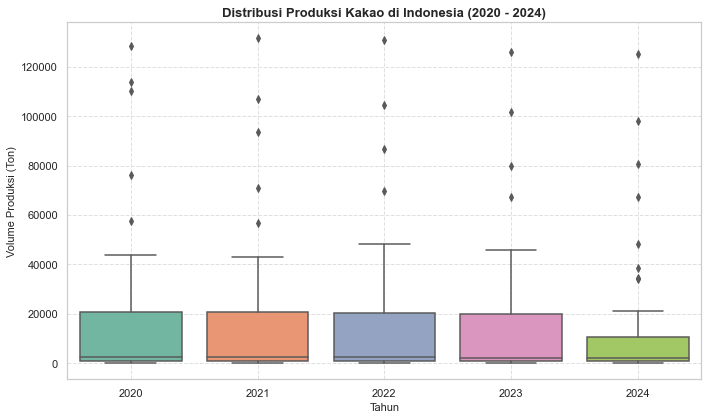

In [3]:
# 202431181_Zhalsabila Amalia Putri

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[tahun_cols], palette="Set2")

plt.title("Distribusi Produksi Kakao di Indonesia (2020 - 2024)", fontsize=13, fontweight='bold')
plt.xlabel("Tahun", fontsize=11)
plt.ylabel("Volume Produksi (Ton)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('grafik_multiboxplot_kakao.png', dpi=300)
plt.show()

### PEMODELAN REGRESI LINIER & EVALUASI

In [4]:
# 202431181_Zhalsabila Amalia Putri

# 1. Menentukan Variabel X dan Y (Dari data bersih)
model_data = df_clean[[2023, 2024]].dropna()
x = model_data[[2023]]
y = model_data[2024]

In [5]:
# 202431181_Zhalsabila Amalia Putri

cek_data = pd.DataFrame({'Produksi_2023 (X)': x.values.flatten(), 'Produksi_2024 (Y)': y.values})
pd.set_option('display.max_rows', None)
display(cek_data)

,Produksi_2023 (X),Produksi_2024 (Y)
0,36595.580000,34169.285000
1,37969.207500,38474.751500
2,36184.492090,34578.981000
3,845.034230,835.492910
4,744.750000,691.000000
5,4728.930860,4396.490000
6,3179.659991,2357.769130
7,45639.409000,48110.793000
8,304.365360,293.221550
9,8.350000,8.750000


In [6]:
# 202431181_Zhalsabila Amalia Putri

# 2. Membagi Data Training dan Testing
x_train, x_test, y_train, y_test = tts(
    x, y, test_size=0.2, random_state=0
)

In [7]:
# 202431181_Zhalsabila Amalia Putri

# 3. Membuat dan Melatih Model
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [8]:
# 202431181_Zhalsabila Amalia Putri

# 4. Melakukan Prediksi pada Data Uji
y_pred = model.predict(x_test)

In [9]:
# 202431181_Zhalsabila Amalia Putri

print("Hasil Prediksi:")
print(y_pred)

Hasil Prediksi:
[  505.64996752  -267.91995367  2217.88360533   365.37959839
  -117.47500556 66095.55238892  4027.66193935  1039.42061392]


In [10]:
# 202431181_Zhalsabila Amalia Putri

# 5. Evaluasi Performa Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


print("HASIL MODEL REGRESI LINEAR")
print("Jumlah data keseluruhan:", len(model_data))
print("Jumlah data training:", len(x_train))
print("Jumlah data testing:", len(x_test))

print("\nPersamaan Regresi:")
print("Coefficient (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)

print("\nEvaluasi Model:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

HASIL MODEL REGRESI LINEAR
Jumlah data keseluruhan: 37
Jumlah data training: 29
Jumlah data testing: 8

Persamaan Regresi:
Coefficient (Slope): 0.989118659450453
Intercept: -323.31059859661036

Evaluasi Model:
MAE : 479.43078479232986
MSE : 305255.04241685866
RMSE: 552.4989071634972
R2 Score: 0.9993550664629474


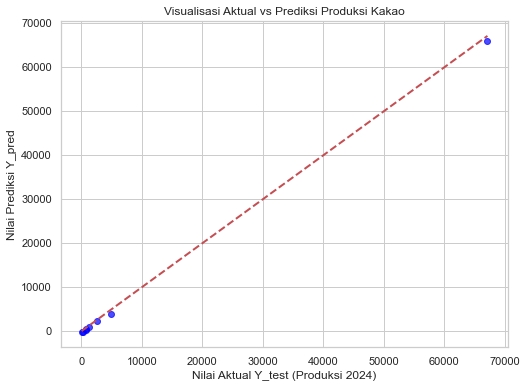

In [11]:
# 202431181_Zhalsabila Amalia Putri

# 6. Visualisasi Grafik Aktual vs Prediksi

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.xlabel("Nilai Aktual Y_test (Produksi 2024)")
plt.ylabel("Nilai Prediksi Y_pred")
plt.title("Visualisasi Aktual vs Prediksi Produksi Kakao")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.show() 



### SOAL 2 - PERHITUNGAN MODEL SECARA MANUAL & VERIFIKASI PYTHON (Menggunakan 10 Data)

In [12]:
# 202431181_Zhalsabila Amalia Putri

# 1. Memfilter dataset untuk mengambil data spesifik (Baris indeks 10 sampai 19)

manual_data = df_clean.iloc[10:20].copy()

In [13]:
# 202431181_Zhalsabila Amalia Putri

# 2. Menyiapkan variabel X (2023) dan Y (2024)
x_sample = manual_data[2023].values
y_sample = manual_data[2024].values
provinsi_sample = manual_data['Provinsi'].values

In [14]:
# 202431181_Zhalsabila Amalia Putri

# Membuat DataFrame khusus untuk tabel penolong / sampel
tabel_penolong = pd.DataFrame({
    'Provinsi': provinsi_sample,
    'X (2023)': x_sample,
    'Y (2024)': y_sample,
    'X * Y': x_sample * y_sample,
    'X^2': x_sample ** 2,
    'Y^2': y_sample ** 2
})

print(" TABEL PENOLONG (SAMPEL PROVINSI 12 - 21) ")
display(tabel_penolong)
print()

 TABEL PENOLONG (SAMPEL PROVINSI 12 - 21) 


,Provinsi,X (2023),Y (2024),X * Y,X^2,Y^2
0,Jawa Barat,696.266510,707.087606,4.923214e+05,4.847871e+05,4.999729e+05
1,Jawa Tengah,1377.722682,1306.725766,1.800306e+06,1.898120e+06,1.707532e+06
2,DI Yogyakarta,1893.440000,2025.930000,3.835977e+06,3.585115e+06,4.104392e+06
3,Jawa Timur,20007.397600,10563.178160,2.113417e+08,4.002960e+08,1.115807e+08
4,Banten,2099.572312,2120.570000,4.452290e+06,4.408204e+06,4.496817e+06
5,Bali,4398.837790,4868.916060,2.141757e+07,1.934977e+07,2.370634e+07
6,Nusa Tenggara Barat,2569.150000,2589.400000,6.652557e+06,6.600532e+06,6.704992e+06
7,Nusa Tenggara Timur,20896.935480,21083.116600,4.405725e+08,4.366819e+08,4.444978e+08
8,Kalimantan Barat,678.200000,604.483000,4.099604e+05,4.599552e+05,3.653997e+05
9,Kalimantan Tengah,1582.810000,1604.630000,2.539824e+06,2.505287e+06,2.574837e+06


In [15]:
# 202431181_Zhalsabila Amalia Putri

# 3. Perhitungan Statistik Dasar 

n = len(x_sample)
sum_x = np.sum(x_sample)
sum_y = np.sum(y_sample)
sum_xy = np.sum(x_sample * y_sample)
sum_x2 = np.sum(x_sample ** 2)

mean_x = np.mean(x_sample)
mean_y = np.mean(y_sample)

print(f"Jumlah Data (n)   : {n}")
print(f"Sum of X (ΣX)     : {sum_x}")
print(f"Sum of Y (ΣY)     : {sum_y}")
print(f"Sum of XY (ΣXY)   : {sum_xy}")
print(f"Sum of X^2 (ΣX^2) : {sum_x2}")
print(f"Rata-rata X (X̄)   : {mean_x:.4f}")
print(f"Rata-rata Y (Ȳ)   : {mean_y:.4f}")
print()

Jumlah Data (n)   : 10
Sum of X (ΣX)     : 56200.332374160535
Sum of Y (ΣY)     : 47474.037192529904
Sum of XY (ΣXY)   : 693515040.5303442
Sum of X^2 (ΣX^2) : 876269645.3096666
Rata-rata X (X̄)   : 5620.0332
Rata-rata Y (Ȳ)   : 4747.4037



In [16]:
# 202431181_Zhalsabila Amalia Putri

# 4. Menghitung Slope (m) dan Intercept (c) secara matematis manual

# Rumus Slope 
slope = (n * sum_xy - sum_x * sum_y) / (n * sum_x2 - (sum_x ** 2))

# Rumus Intercept 
intercept = mean_y - slope * mean_x

print("HASIL PERHITUNGAN KOEFISIEN ")
print(f"Slope (m)     : {slope:.6f}")
print(f"Intercept (c) : {intercept:.6f}")
print(f"Persamaan     : Y = {slope:.4f}X + {intercept:.4f}")
print()

HASIL PERHITUNGAN KOEFISIEN 
Slope (m)     : 0.761407
Intercept (c) : 468.268978
Persamaan     : Y = 0.7614X + 468.2690



In [17]:
# 202431181_Zhalsabila Amalia Putri

# 5. Simulasi Prediksi untuk Provinsi Jawa Barat (Baris pertama pada sampel)

# Mengambil data Jawa Barat (X = 696)
x_jabar = x_sample[0]
y_aktual_jabar = y_sample[0]
y_pred_jabar = slope * x_jabar + intercept

print("SIMULASI PREDIKSI (CONTOH: JAWA BARAT) ")
print(f"Provinsi         : {provinsi_sample[0]}")
print(f"Produksi 2023 (X): {x_jabar}")
print(f"Produksi 2024 (Aktual) : {y_aktual_jabar}")
print(f"Produksi 2024 (Prediksi): {y_pred_jabar:.2f}")
print(f"Selisih (Error)  : {abs(y_aktual_jabar - y_pred_jabar):.2f}")

SIMULASI PREDIKSI (CONTOH: JAWA BARAT) 
Provinsi         : Jawa Barat
Produksi 2023 (X): 696.26651
Produksi 2024 (Aktual) : 707.0876063200001
Produksi 2024 (Prediksi): 998.41
Selisih (Error)  : 291.32


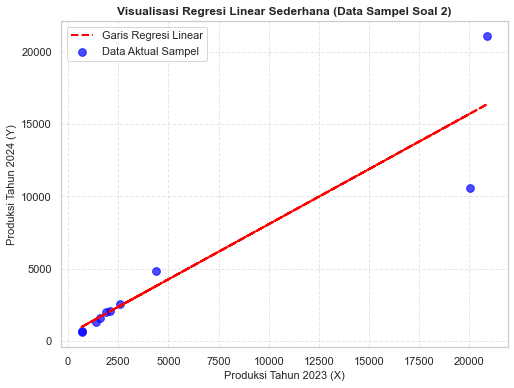

In [18]:
# 202431181_Zhalsabila Amalia Putri

# Visualisasi Grafik Regresi Linear (Data Sampel Soal 2)

plt.figure(figsize=(8, 6))

# Scatter plot titik-titik data aktual sampel (Provinsi No. 12 - 21)
plt.scatter(x_sample, y_sample, color='blue', alpha=0.7, s=60, label='Data Aktual Sampel')

# Membuat garis regresi berdasarkan rumus yang sudah dihitung (Y = slope * X + intercept)
y_line = slope * x_sample + intercept
plt.plot(x_sample, y_line, color='red', linestyle='--', linewidth=2, label='Garis Regresi Linear')


plt.xlabel("Produksi Tahun 2023 (X)", fontsize=11)
plt.ylabel("Produksi Tahun 2024 (Y)", fontsize=11)
plt.title("Visualisasi Regresi Linear Sederhana (Data Sampel Soal 2)", fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()
